In [3]:
# --- project root: run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

working folder: <project folder>


# 17a — Round 7: download 20 new TRAINING regions (keeps all earlier work)

**Why:** on new places (Nujivid, Hanuman Junction) the models call **rice paddies "Wetland"**: a flooded paddy looks like a marsh
to radar, and none of the training regions taught the model that "flooded for 1–2 months, then growing" means *Cropland*.
v6 also rarely finds **Grass/Shrub**, and confuses **trees in cities** with Built-up.

**What is added (all TRAINING regions; validation and test regions stay the same, so v7 is directly comparable with v5 / v6):**

| Group | Regions | What the model should learn |
|---|---|---|
| Rice paddies (WorldCover: Cropland) | central Thailand, Bangladesh, West Bengal, Tamil Nadu (Cauvery delta), Java, Philippines, Arkansas, California, Vercelli (Italy) | flooded-then-growing fields are **Cropland**, not Wetland |
| Natural wetlands | Iberá (Argentina), Kakadu (Australia), Doñana (Spain), Niger Delta mangroves, Hudson Bay lowlands, Vasyugan bog (Siberia) | what **real** wetland looks like over a year (wet for many months, no harvest) |
| Grass / Shrub | Patagonian steppe, Texas rangeland, Australian shrubland | the weakest class |
| Tropical cities with trees | Kuala Lumpur, Chennai | trees between buildings, South-Indian city |

Every new region is at least 30 km from all 52 existing regions and more than 150 km from the places you test on
(Nujivid, Hanuman Junction, Vijayawada, Frankfurt, Munich), so those stay fair tests.

**Check the class table in Section 3 before downloading.** WorldCover decides the labels: if a "wetland" region turns out to be
mostly Grass (bogs are sometimes mapped as moss = Grass/Shrub) or a "rice" region mostly Trees, set `USE = False` for it.

Writes `data/regions_r7.csv` and only *adds* new files to `data/raw/` (~20 × 50 MB). Next: **17b_preprocess_r7.ipynb**.

## 0. Packages and Earth Engine login

In [4]:
import importlib, subprocess, sys
for pkg, mod in [("earthengine-api", "ee"), ("rasterio", "rasterio"), ("tqdm", "tqdm"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "-q",
                               "--no-warn-script-location", pkg])
        print("installed", pkg)
print("packages ok — if anything was installed, restart the kernel once (Kernel → Restart Kernel) and continue from the next cell")

import urllib.request
try:
    urllib.request.urlopen("https://earthengine.googleapis.com", timeout=10); print("Internet OK")
except Exception as e:
    print("Internet problem:", e)

packages ok — if anything was installed, restart the kernel once (Kernel → Restart Kernel) and continue from the next cell
Internet problem: HTTP Error 404: Not Found


In [5]:
import ee
PROJECT = "your-ee-project"     # your Earth Engine Cloud project
try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate(auth_mode="notebook")
    ee.Initialize(project=PROJECT)
print("Earth Engine OK:", ee.ImageCollection("COPERNICUS/S1_GRD").limit(1).size().getInfo() == 1)

~/.local/lib/python3.11/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.74.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


Earth Engine OK: True


In [6]:
import time, json
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import transform as warp_transform
from tqdm.auto import tqdm

YEAR      = 2021
SIZE_M    = 12_000                     # region side length in metres (12 km)
RES       = 10                         # pixel size in metres
N_PIX     = SIZE_M // RES              # 1200 x 1200 pixels per region
DATA      = Path("data")
RAW       = DATA / "raw"
RAW.mkdir(parents=True, exist_ok=True)
print("Saving to:", RAW.resolve())

Saving to: <project folder>/data/raw


## 1. Regions
The 52 existing regions are read from `data/regions_r5.csv` (unchanged). The new ones are listed below — all `train`.

In [7]:
# name, lat, lon, main reason it is included          (all new regions are TRAINING regions)
NEW = [
    # ---- rice paddies: WorldCover = Cropland, radar = flooded for 1-2 months, then fast growth ----------
    ("thai_rice",          14.750,  100.250, "Cropland (rice, Thailand)"),
    ("bangladesh_rice",    24.600,   89.800, "Cropland (rice, Bangladesh)"),
    ("bengal_rice",        23.200,   87.900, "Cropland (rice, West Bengal)"),
    ("cauvery_rice",       10.800,   79.250, "Cropland (rice, Tamil Nadu delta)"),
    ("java_rice",          -6.250,  107.400, "Cropland (rice, Java)"),
    ("luzon_rice",         15.650,  120.850, "Cropland (rice, Philippines)"),
    ("arkansas_rice",      34.550,  -91.550, "Cropland (rice, USA)"),
    ("sacramento_rice",    39.300, -121.900, "Cropland (rice, California)"),
    ("vercelli_rice",      45.300,    8.350, "Cropland (rice, Italy)"),
    # ---- natural wetlands: wet for many months, no harvest -----------------------------------------------
    ("ibera_wetland",     -28.400,  -57.200, "Wetland (marsh, Argentina)"),
    ("kakadu_floodplain", -12.400,  132.550, "Wetland (floodplain, Australia)"),
    ("donana_marsh",       37.000,   -6.350, "Wetland (marsh, Spain)"),
    ("niger_mangrove",      4.500,    6.700, "Wetland (mangrove, Nigeria)"),
    ("hudson_lowlands",    52.500,  -84.000, "Wetland (peatland, Canada)"),
    ("vasyugan_bog",       57.200,   78.500, "Wetland (bog, Siberia)"),
    # ---- grass / shrub (weakest class) --------------------------------------------------------------------
    ("patagonia_steppe",  -46.500,  -70.500, "Grass/Shrub (steppe)"),
    ("texas_rangeland",    31.000, -100.800, "Grass/Shrub (rangeland)"),
    ("australia_shrub",   -31.000,  143.500, "Grass/Shrub (shrubland)"),
    # ---- tropical / South-Asian cities with trees ---------------------------------------------------------
    ("kuala_lumpur",        3.100,  101.650, "Built-up + Trees (tropical city)"),
    ("chennai",            13.050,   80.200, "Built-up (South-Indian city)"),
]
USE = {n[0]: True for n in NEW}          # set e.g. USE["vasyugan_bog"] = False after the check in Section 3

old = pd.read_csv(DATA / "regions_r5.csv")
new = pd.DataFrame(NEW, columns=["name", "lat", "lon", "reason"]).assign(split="train", round=7)
new = new[new.name.map(USE)]

# --- distance checks: no overlap with existing regions, far from the places used for testing
TEST_PLACES = {"Nujivid": (16.78, 80.85), "Hanuman_Junction": (16.64, 80.97), "Vijayawada": (16.51, 80.65),
               "Frankfurt": (50.11, 8.68), "Munich": (48.14, 11.58)}
def km(a, b, c, d):
    p1, p2 = np.radians(a), np.radians(c)
    h = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(d - b) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(h))
for r in new.itertuples():
    d_old = min(km(r.lat, r.lon, o.lat, o.lon) for o in old.itertuples())
    d_test = min(km(r.lat, r.lon, *p) for p in TEST_PLACES.values())
    assert d_old > 30, f"{r.name} is only {d_old:.0f} km from an existing region"
    assert d_test > 150, f"{r.name} is only {d_test:.0f} km from a test place"
print(f"distance checks passed: {len(new)} new regions, all > 30 km from the 52 old ones and > 150 km from the test places")
print(len(old), "existing +", len(new), "new =", len(old) + len(new), "regions")
new

distance checks passed: 20 new regions, all > 30 km from the 52 old ones and > 150 km from the test places
52 existing + 20 new = 72 regions


,name,lat,lon,reason,split,round
0,thai_rice,14.75,100.25,"Cropland (rice, Thailand)",train,7
1,bangladesh_rice,24.60,89.80,"Cropland (rice, Bangladesh)",train,7
2,bengal_rice,23.20,87.90,"Cropland (rice, West Bengal)",train,7
3,cauvery_rice,10.80,79.25,"Cropland (rice, Tamil Nadu delta)",train,7
4,java_rice,-6.25,107.40,"Cropland (rice, Java)",train,7
5,luzon_rice,15.65,120.85,"Cropland (rice, Philippines)",train,7
6,arkansas_rice,34.55,-91.55,"Cropland (rice, USA)",train,7
7,sacramento_rice,39.30,-121.90,"Cropland (rice, California)",train,7
8,vercelli_rice,45.30,8.35,"Cropland (rice, Italy)",train,7
9,ibera_wetland,-28.40,-57.20,"Wetland (marsh, Argentina)",train,7


## 2. Helper functions (identical to 01c, so the new data is processed exactly like the old)

In [8]:
def utm_epsg(lat, lon):
    zone = int((lon + 180) // 6) + 1
    return f"EPSG:{(32600 if lat >= 0 else 32700) + zone}"

def region_grid(lat, lon):
    crs = utm_epsg(lat, lon)
    xs, ys = warp_transform("EPSG:4326", crs, [lon], [lat])
    x0 = round((xs[0] - SIZE_M / 2) / RES) * RES     # top-left corner, snapped to 10 m
    y0 = round((ys[0] + SIZE_M / 2) / RES) * RES
    grid = {"dimensions": {"width": N_PIX, "height": N_PIX},
            "affineTransform": {"scaleX": RES, "shearX": 0, "translateX": x0,
                                "shearY": 0, "scaleY": -RES, "translateY": y0},
            "crsCode": crs}
    aoi = ee.Geometry.Rectangle([x0, y0 - SIZE_M, x0 + SIZE_M, y0],
                                proj=crs, geodesic=False)
    return crs, x0, y0, grid, aoi

def s1_collection(aoi, start, end, orbit):
    return (ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(aoi).filterDate(start, end)
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
            .filter(ee.Filter.eq("resolution_meters", 10))
            .filter(ee.Filter.eq("orbitProperties_pass", orbit)))

def s1_month(aoi, year, month, orbit):
    start = ee.Date.fromYMD(year, month, 1)
    col = s1_collection(aoi, start, start.advance(1, "month"), orbit)
    def to_linear(img):
        vv_vh = img.select(["VV", "VH"])
        vv_vh = vv_vh.updateMask(img.select("VV").gt(-30))      # remove edge noise
        return ee.Image(10).pow(vv_vh.divide(10))                 # dB -> linear power
    mean_lin = col.map(to_linear).mean()                          # average in LINEAR
    db = mean_lin.log10().multiply(10)                            # back to dB
    ratio = db.select("VV").subtract(db.select("VH")).rename("VV_VH")
    out = db.addBands(ratio).select(["VV", "VH", "VV_VH"])
    return out.multiply(100).round().unmask(-9999).toInt16()      # dB x 100

WORLDCOVER = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")   # = 2021

## 3. Check the new regions before downloading
Images per month (best orbit) and the WorldCover class mix. **Look at the class table:** each region should mostly contain the
class it was chosen for. Turn a region off with `USE["name"] = False` in Section 1 and re-run from there if it doesn't.

In [9]:
from collections import Counter

def check_region(lat, lon):
    crs, x0, y0, grid, aoi = region_grid(lat, lon)
    col = s1_collection(aoi, f"{YEAR}-01-01", f"{YEAR + 1}-01-01", "ASCENDING") \
            .merge(s1_collection(aoi, f"{YEAR}-01-01", f"{YEAR + 1}-01-01", "DESCENDING"))
    hist = WORLDCOVER.reduceRegion(ee.Reducer.frequencyHistogram(), aoi,
                                   scale=RES, crs=crs, maxPixels=1e9).get("Map")
    info = ee.Dictionary({"time": col.aggregate_array("system:time_start"),
                          "pass": col.aggregate_array("orbitProperties_pass"),
                          "hist": hist}).getInfo()
    months = pd.to_datetime(info["time"], unit="ms").month
    counts = {p: Counter(m for m, q in zip(months, info["pass"]) if q == p)
              for p in ("ASCENDING", "DESCENDING")}
    def score(p):   # months with >= 2 images first, then total images
        return (sum(counts[p][m] >= 2 for m in range(1, 13)), sum(counts[p].values()))
    orbit = max(("DESCENDING", "ASCENDING"), key=score)
    n_month = [counts[orbit][m] for m in range(1, 13)]
    return orbit, n_month, {int(k): v for k, v in (info["hist"] or {}).items()}

rows, hists = [], {}
for r in tqdm(new.itertuples(), total=len(new)):
    orbit, n_month, hist = check_region(r.lat, r.lon)
    hists[r.name] = hist
    rows.append({"name": r.name, "orbit": orbit, "min_images": min(n_month),
                 "images_per_month": " ".join(map(str, n_month))})
check = pd.DataFrame(rows)
new = new.drop(columns=[c for c in ["orbit", "min_images", "images_per_month"] if c in new]).merge(check, on="name")
regions = pd.concat([old.assign(round=old.get("round", 5)), new], ignore_index=True)
regions.to_csv(DATA / "regions_r7.csv", index=False)
with open(DATA / "worldcover_histograms_r7_new.json", "w") as f:
    json.dump(hists, f)
new[["name", "reason", "orbit", "min_images", "images_per_month"]]

  0%|          | 0/20 [00:00<?, ?it/s]

,name,reason,orbit,min_images,images_per_month
0,thai_rice,"Cropland (rice, Thailand)",DESCENDING,5,7 8 7 8 6 6 5 6 7 8 7 7
1,bangladesh_rice,"Cropland (rice, Bangladesh)",DESCENDING,2,2 3 2 3 2 3 2 3 2 3 2 3
2,bengal_rice,"Cropland (rice, West Bengal)",DESCENDING,2,3 2 3 2 3 2 3 2 3 2 3 3
3,cauvery_rice,"Cropland (rice, Tamil Nadu delta)",DESCENDING,1,1 3 2 3 2 3 3 2 3 2 2 2
4,java_rice,"Cropland (rice, Java)",ASCENDING,2,4 6 2 6 4 6 6 4 6 4 3 4
5,luzon_rice,"Cropland (rice, Philippines)",ASCENDING,2,3 2 3 2 3 2 3 2 4 2 3 2
6,arkansas_rice,"Cropland (rice, USA)",ASCENDING,4,6 4 5 4 5 5 5 5 5 5 5 5
7,sacramento_rice,"Cropland (rice, California)",ASCENDING,8,10 10 10 10 10 9 9 10 10 11 10 8
8,vercelli_rice,"Cropland (rice, Italy)",ASCENDING,10,14 10 13 12 14 11 13 13 12 13 12 11
9,ibera_wetland,"Wetland (marsh, Argentina)",DESCENDING,4,5 4 6 5 5 5 5 5 4 5 5 4


In [10]:
# Class mix of the NEW regions (our 7 classes, % of pixels)
import sys; sys.path.append(".")
from preprocess import CLASSES, WORLDCOVER_TO_CLASS

def to_classes(hist):
    v = np.zeros(len(CLASSES))
    for code, n in hist.items():
        if code in WORLDCOVER_TO_CLASS:
            v[WORLDCOVER_TO_CLASS[code]] += n
    return v

mix = pd.DataFrame({n: to_classes(h) for n, h in hists.items()}, index=CLASSES).T
mix_pct = (100 * mix.div(mix.sum(axis=1), axis=0)).round(1)
mix_pct.insert(0, "chosen for", new.set_index("name").reason)
print("Class share per NEW region (%)")
display(mix_pct)
print("Class share over all new regions together (%)")
display((100 * mix.sum() / mix.values.sum()).round(1).to_frame("%").T)

Class share per NEW region (%)


,chosen for,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
thai_rice,"Cropland (rice, Thailand)",13.4,6.6,74.2,4.9,0.2,0.6,0.0
bangladesh_rice,"Cropland (rice, Bangladesh)",22.0,2.7,53.0,0.5,1.0,20.2,0.6
bengal_rice,"Cropland (rice, West Bengal)",18.4,2.4,63.2,11.1,1.4,3.4,0.0
cauvery_rice,"Cropland (rice, Tamil Nadu delta)",17.8,2.8,77.1,1.7,0.3,0.2,0.0
java_rice,"Cropland (rice, Java)",6.2,0.3,84.4,9.1,0.0,0.0,0.0
luzon_rice,"Cropland (rice, Philippines)",9.6,1.0,85.8,3.4,0.2,0.1,0.0
arkansas_rice,"Cropland (rice, USA)",9.0,9.6,72.6,2.8,0.4,5.5,0.1
sacramento_rice,"Cropland (rice, California)",26.2,25.8,33.8,0.4,1.0,0.7,12.2
vercelli_rice,"Cropland (rice, Italy)",2.7,2.3,87.4,7.2,0.2,0.3,0.0
ibera_wetland,"Wetland (marsh, Argentina)",0.0,0.0,0.0,0.0,0.0,2.7,97.2


Class share over all new regions together (%)


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
%,16.4,21.7,32.3,8.9,1.5,3.4,15.9


## 4. Download the new regions
Same code as 01c. Regions that already exist are skipped, so you can stop and re-run any time. About 3–6 minutes per region.

In [11]:
def fetch(expression, grid, tries=5):
    for k in range(tries):
        try:
            return ee.data.computePixels({"expression": expression,
                                          "fileFormat": "NUMPY_NDARRAY", "grid": grid})
        except Exception as e:                      # quota / network hiccup -> wait, retry
            if k == tries - 1:
                raise
            wait = 10 * (k + 1)
            print(f"   retry in {wait}s ({str(e)[:80]})")
            time.sleep(wait)

def download_region(r):
    s1_path, lab_path = RAW / f"{r.name}_s1_{YEAR}.tif", RAW / f"{r.name}_label.tif"
    if s1_path.exists() and lab_path.exists():
        return "skipped (already downloaded)"
    crs, x0, y0, grid, aoi = region_grid(r.lat, r.lon)
    profile = dict(driver="GTiff", width=N_PIX, height=N_PIX, crs=crs,
                   transform=from_origin(x0, y0, RES, RES),
                   compress="deflate", tiled=True, blockxsize=256, blockysize=256)

    # --- Sentinel-1: 12 months x 3 bands
    n_img = [int(v) for v in str(r.images_per_month).split()]      # images per month (from Section 3)
    def one_month(m):
        if n_img[m - 1] == 0:                                     # no image this month -> empty month (no data)
            return np.full((3, N_PIX, N_PIX), -9999, np.int16)
        a = fetch(s1_month(aoi, YEAR, m, r.orbit), grid)
        return np.stack([a["VV"], a["VH"], a["VV_VH"]]).astype(np.int16)
    with ThreadPoolExecutor(max_workers=4) as pool:
        months = list(pool.map(one_month, range(1, 13)))
    stack = np.concatenate(months)                        # (36, 1200, 1200)
    tmp = s1_path.with_suffix(".tmp")
    with rasterio.open(tmp, "w", count=36, dtype="int16", nodata=-9999,
                       predictor=2, **profile) as dst:
        dst.write(stack)
        for m in range(12):
            for b, band in enumerate(["VV", "VH", "VV_VH"]):
                dst.set_band_description(3 * m + b + 1, f"{YEAR}-{m + 1:02d}_{band}")
        dst.update_tags(units="dB x 100", orbit=r.orbit, source="COPERNICUS/S1_GRD")
    tmp.replace(s1_path)                                  # only complete files get the real name

    # --- WorldCover label (nearest neighbour: class codes stay whole numbers)
    lab = fetch(WORLDCOVER.unmask(0).toUint8(), grid)["Map"].astype(np.uint8)
    with rasterio.open(lab_path, "w", count=1, dtype="uint8", nodata=0, **profile) as dst:
        dst.write(lab, 1)
        dst.update_tags(source="ESA/WorldCover/v200 (2021)", values="original WorldCover codes")
    return "done"

t0 = time.time()
for r in tqdm(list(new.itertuples()), desc="new regions"):
    print(f"{r.name:16s} {r.orbit:10s} ->", download_region(r))
print(f"Finished in {(time.time() - t0) / 60:.1f} min")

new regions:   0%|          | 0/20 [00:00<?, ?it/s]

thai_rice        DESCENDING -> skipped (already downloaded)
bangladesh_rice  DESCENDING -> skipped (already downloaded)
bengal_rice      DESCENDING -> skipped (already downloaded)
cauvery_rice     DESCENDING -> skipped (already downloaded)
java_rice        ASCENDING  -> skipped (already downloaded)
luzon_rice       ASCENDING  -> skipped (already downloaded)
arkansas_rice    ASCENDING  -> skipped (already downloaded)
sacramento_rice  ASCENDING  -> skipped (already downloaded)
vercelli_rice    ASCENDING  -> skipped (already downloaded)
ibera_wetland    DESCENDING -> skipped (already downloaded)
kakadu_floodplain DESCENDING -> skipped (already downloaded)
donana_marsh     ASCENDING  -> skipped (already downloaded)
niger_mangrove   ASCENDING  -> skipped (already downloaded)
hudson_lowlands  ASCENDING  -> skipped (already downloaded)
vasyugan_bog     DESCENDING -> done
patagonia_steppe ASCENDING  -> done
texas_rangeland  ASCENDING  -> done
australia_shrub  DESCENDING -> done
kuala_lumpur   

## 5. Quick check of the downloaded files

In [12]:
import matplotlib.pyplot as plt
from preprocess import decode_s1

qc = []
for r in new.itertuples():
    s1p, lp = RAW / f"{r.name}_s1_{YEAR}.tif", RAW / f"{r.name}_label.tif"
    with rasterio.open(s1p) as a, rasterio.open(lp) as b:
        same = (a.shape == b.shape) and (a.crs == b.crs) and (a.transform == b.transform)
        raw = a.read(); shape = a.shape
    nod = (raw.reshape(12, 3, -1)[:, 0] == -9999).mean(1) * 100
    qc.append({"name": r.name, "aligned": same, "shape": shape,
               "max nodata % (month)": round(nod.max(), 1),
               "nodata % per month": " ".join(f"{v:.0f}" for v in nod),
               "MB on disk": round((s1p.stat().st_size + lp.stat().st_size) / 1e6, 1)})
qc = pd.DataFrame(qc)
print("All regions aligned:", qc.aligned.all(), "| total size:", round(qc["MB on disk"].sum() / 1e3, 2), "GB")
qc

All regions aligned: True | total size: 1.5 GB


,name,aligned,shape,max nodata % (month),nodata % per month,MB on disk
0,thai_rice,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,74.6
1,bangladesh_rice,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,77.0
2,bengal_rice,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,76.3
3,cauvery_rice,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,76.2
4,java_rice,True,"(1200, 1200)",0.1,0 0 0 0 0 0 0 0 0 0 0 0,76.1
5,luzon_rice,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,75.8
6,arkansas_rice,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,74.5
7,sacramento_rice,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,73.0
8,vercelli_rice,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,72.2
9,ibera_wetland,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,73.3


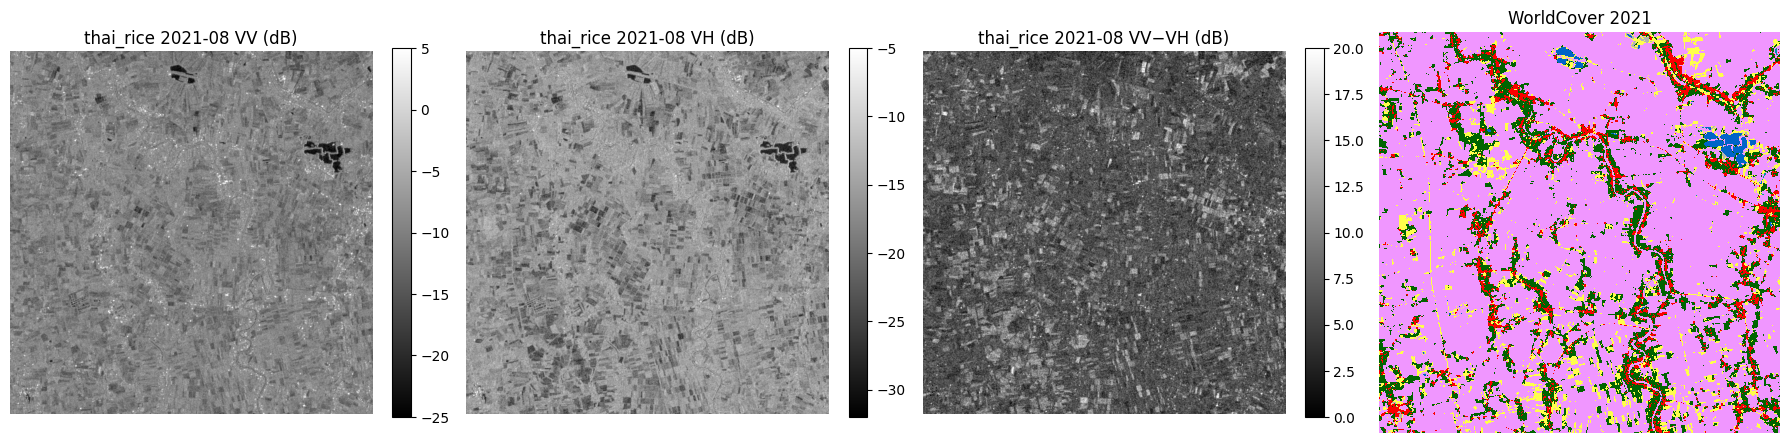

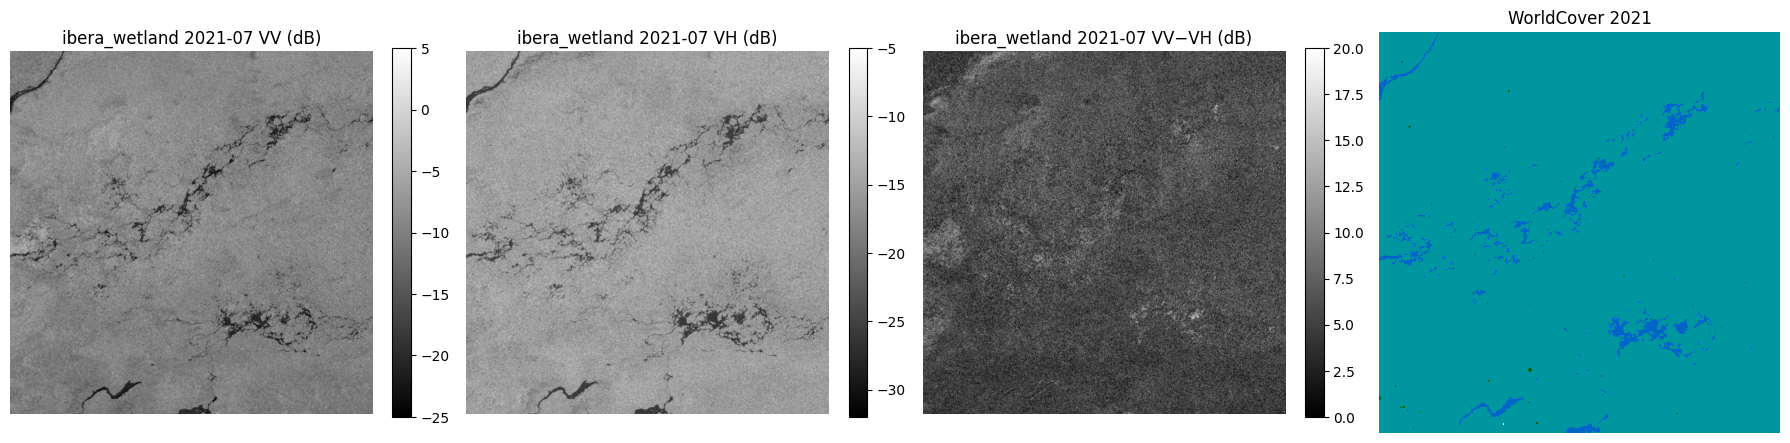

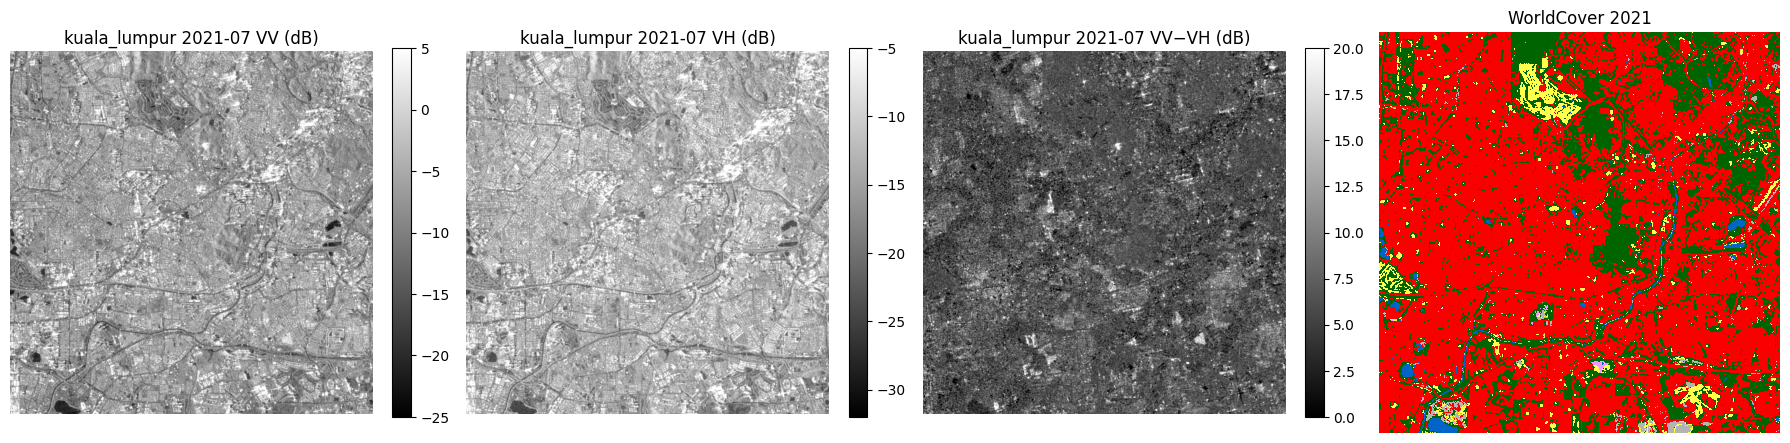

In [13]:
from matplotlib.colors import ListedColormap, BoundaryNorm
WC_CODES  = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]
WC_COLORS = ["#006400", "#ffbb22", "#ffff4c", "#f096ff", "#fa0000", "#b4b4b4",
             "#f0f0f0", "#0064c8", "#0096a0", "#00cf75", "#fae6a0"]   # official WorldCover colours
wc_cmap = ListedColormap(WC_COLORS)
wc_norm = BoundaryNorm(WC_CODES + [101], wc_cmap.N)

def show_region(name, month=7):
    with rasterio.open(RAW / f"{name}_s1_{YEAR}.tif") as f:
        x = decode_s1(f.read().reshape(12, 3, N_PIX, N_PIX))[month - 1]
    with rasterio.open(RAW / f"{name}_label.tif") as f:
        y = f.read(1)
    fig, ax = plt.subplots(1, 4, figsize=(18, 5))
    for a, img, t, lim in zip(ax, x, ["VV (dB)", "VH (dB)", "VV−VH (dB)"],
                              [(-25, 5), (-32, -5), (0, 20)]):
        im = a.imshow(img, cmap="gray", vmin=lim[0], vmax=lim[1]); a.set_title(f"{name} {YEAR}-{month:02d} {t}")
        plt.colorbar(im, ax=a, fraction=0.046)
    ax[3].imshow(y, cmap=wc_cmap, norm=wc_norm, interpolation="nearest"); ax[3].set_title("WorldCover 2021")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

show_region("thai_rice", month=8)          # rice: dark (flooded) fields in some months
show_region("ibera_wetland", month=7)
show_region("kuala_lumpur", month=7)

✅ When the tables look fine and the images line up, continue with **17b_preprocess_r7.ipynb**.